# 3 STATISTICAL ANALYSIS

**Project:** Irish Company Survival: Registrations, Cohort Survival and Prediction

**Author:** Temuulen Bulgan

### Purpose of this notebook
This notebook shows how many companies were registered each year, how many were still registered 1, 3 and 5 years later, which sectors survived best, and whether Dublin companies survive longer than companies in other counties. It adds confidence intervals to the survival rates, tests whether the sector mix explains the Dublin gap, and checks whether the results depend on the definition of "closed" and the start year.

### Input
Tables in the SQL Server database `irish_company_survival` (loaded by notebook 2).

### Output
- Figures in `figures/` (`03_*.png`)
- Summary of findings and limitations at the end of this notebook

## Setup

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text

#### Connect to the database

In [2]:
# Connection to the local SQL Server database
connection_string = (
    "mssql+pyodbc://@localhost/irish_company_survival"
    "?driver=ODBC+Driver+18+for+SQL+Server"
    "&trusted_connection=yes"
    "&TrustServerCertificate=yes"
)
engine = create_engine(connection_string)

# Check the connection
with engine.connect() as conn:
    database_name = conn.execute(text("SELECT DB_NAME()")).scalar()

print("Connected to:", database_name)

Connected to: irish_company_survival


## 1. Load the data

I read one row per company from SQL. The query joins the fact table to the county, sector and status tables, so each company has its county, sector section and both closed flags. I use LEFT JOIN for county and sector so that companies without them are kept. Then I check the size, the missing values and the date range against notebook 2.

In [3]:
# One row per company, with county, sector and closed flags from the dimension tables
query = """
SELECT f.company_num,
       f.reg_date,
       f.closed_date,
       c.county,
       s.nace_section,
       s.section_name,
       st.closed,
       st.closed_strict
FROM fact_company AS f
LEFT JOIN dim_county AS c ON f.county_id = c.county_id
LEFT JOIN dim_sector AS s ON f.sector_id = s.sector_id
JOIN dim_status AS st ON f.status_id = st.status_id
"""
companies = pd.read_sql(text(query), engine, parse_dates=["reg_date", "closed_date"])

# Checks
print("Shape:", companies.shape, "\n")
print("Missing values:")
print(companies.isna().sum(), "\n")
print("Registration dates:", companies["reg_date"].min().date(), "to", companies["reg_date"].max().date())
print("Closing dates:     ", companies["closed_date"].min().date(), "to", companies["closed_date"].max().date())

Shape: (512008, 8) 

Missing values:
company_num           0
reg_date              0
closed_date      305953
county             1822
nace_section     246119
section_name     246119
closed                0
closed_strict         0
dtype: int64 

Registration dates: 2000-01-01 to 2026-10-27
Closing dates:      2000-07-13 to 2026-10-21


The table has 512,008 companies and 8 columns, the same as `fact_company` in notebook 2. 305,953 companies have no closing date, 1,822 have no county and 246,119 have no sector section. `nace_section` and `section_name` have the same number of missing values, so every company with a sector code has a section. Registration dates run from 2000-01-01 to 2026-10-27 and closing dates from 2000-07-13 to 2026-10-21.

## 2. Registrations per year

This section looks at how many companies were registered each year. I count the companies by registration year and check the totals against SQL Query 1.1.

In [4]:
# Year of registration, used for the yearly counts and later for the cohorts
companies["reg_year"] = companies["reg_date"].dt.year

# Number of companies registered each year
registrations = companies.groupby("reg_year").size()

# Checks against SQL Query 1.1
print("Years:", len(registrations))
print("Total:", registrations.sum(), "\n")
print(registrations)

Years: 27
Total: 512008 

reg_year
2000    18247
2001    14374
2002    13860
2003    14384
2004    15696
2005    17325
2006    19328
2007    18820
2008    14834
2009    13465
2010    14160
2011    14765
2012    14169
2013    15690
2014    17987
2015    19561
2016    21047
2017    22408
2018    22518
2019    22796
2020    21924
2021    25669
2022    21637
2023    22581
2024    23835
2025    26533
2026    24395
dtype: int64


There are 27 registration years, from 2000 to 2026, with 512,008 companies in total, the same as SQL Query 1.1. 2026 is not a full year: the data ends on 2026-10-27 (section 1), so its count of 24,395 covers less than ten months.

### 2.1 Chart of yearly registrations

The chart shows complete years only. The data ends on 2026-10-27, so 2026 is left out: its count would look like a fall. The dashed lines mark the Brexit referendum (2016) and the start of COVID-19 restrictions in Ireland (2020).

#### Background: Brexit and COVID-19

- The UK voted to leave the EU in a referendum on 23 June 2016.
- On 12 March 2020 the Irish Government closed schools, colleges and childcare and asked people to work from home where possible, the first COVID-19 restrictions in Ireland.

Sources: [Results of the 2016 UK EU membership referendum](https://en.wikipedia.org/wiki/Results_of_the_2016_United_Kingdom_European_Union_membership_referendum); [gov.ie, "Updated measures in response to COVID-19 (Coronavirus), Thursday 12 March"](https://www.gov.ie/en/department-of-health/publications/updated-measures-in-response-to-covid-19-coronavirus-thursday-12-march/)

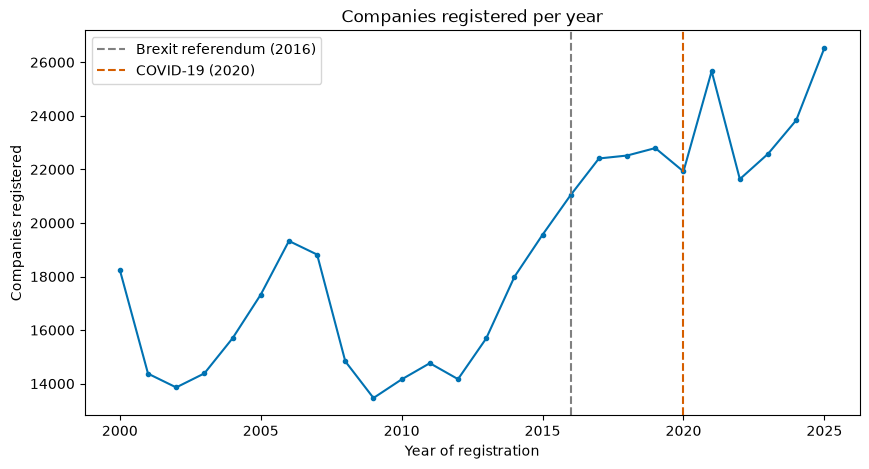

Years in chart: 2000 to 2025


In [6]:
# Last year in the data is not complete, so the chart stops one year before it
last_year = companies["reg_date"].max().year
complete_registrations = registrations.loc[:last_year - 1]

# Line chart of yearly registrations
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(complete_registrations.index, complete_registrations.values,
        marker="o", markersize=3, color="#0072B2")

# Brexit referendum and start of COVID-19
ax.axvline(2016, color="grey", linestyle="--", label="Brexit referendum (2016)")
ax.axvline(2020, color="#D55E00", linestyle="--", label="COVID-19 (2020)")

ax.set_title("Companies registered per year")
ax.set_xlabel("Year of registration")
ax.set_ylabel("Companies registered")
ax.legend()

fig.savefig("../figures/03_registrations_per_year.png", dpi=150, bbox_inches="tight")
plt.show()

# Check: years in the chart
print("Years in chart:", complete_registrations.index.min(), "to", complete_registrations.index.max())

Registrations fell from 18,247 in 2000 to 13,860 in 2002, rose to 19,328 in 2006 and fell to their lowest level, 13,465, in 2009. From 2010 they rose almost every year. In 2020 they dipped slightly, from 22,796 to 21,924, then rose to 25,669 in 2021 and fell to 21,637 in 2022. The highest year is 2025, with 26,533 companies. Registrations were already rising before 2016, so the chart alone does not show a Brexit effect.

### 2.2 Registrations by county

I count the companies in each county, for all registrations in the data (2000-01-01 to 2026-10-27, from section 1). Companies with no county are shown as `NaN`.

In [7]:
# Companies per county, largest first, including companies with no county
county_counts = companies["county"].value_counts(dropna=False)

# Dublin's share of all companies, in percent
dublin_share = county_counts.loc["DUBLIN"] / len(companies) * 100

print("Counties:", companies["county"].nunique())
print("Dublin share:", round(dublin_share, 1), "%\n")
print(county_counts)

Counties: 26
Dublin share: 44.4 %

county
DUBLIN       227457
CORK          51450
GALWAY        22117
KILDARE       19791
MEATH         17961
LIMERICK      17288
WICKLOW       13278
LOUTH         13191
DONEGAL       11492
WEXFORD       11477
KERRY         11368
TIPPERARY     11313
CLARE         10631
WATERFORD      8610
MAYO           8286
WESTMEATH      8200
KILKENNY       6905
CAVAN          5906
OFFALY         5411
LAOIS          5178
MONAGHAN       5129
CARLOW         4435
SLIGO          4239
ROSCOMMON      3957
LONGFORD       2838
LEITRIM        2278
NaN            1822
Name: count, dtype: int64


Companies are registered in all 26 counties. Dublin has 227,457 companies, 44.4% of the total, and Cork is second with 51,450. Leitrim has the fewest, 2,278. 1,822 companies have no county. The counts match SQL Query 1.3.

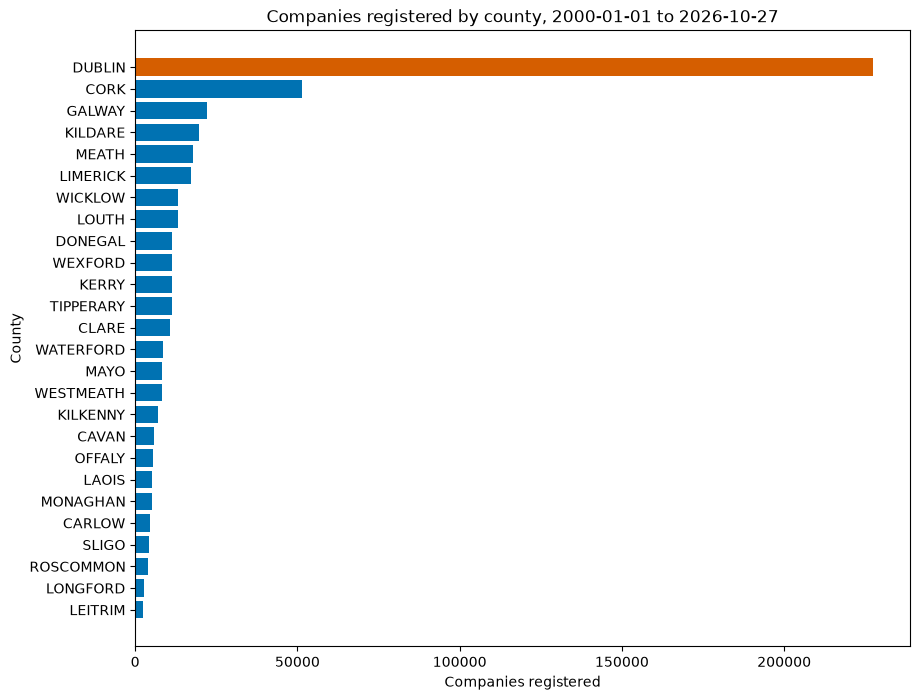

Counties in chart: 26


In [9]:
# Counties only (no missing values), smallest first so the largest bar is at the top
county_chart = companies["county"].value_counts().sort_values()

# Dublin in orange, all other counties in blue
bar_colours = ["#D55E00" if county == "DUBLIN" else "#0072B2" for county in county_chart.index]

# Horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(county_chart.index, county_chart.values, color=bar_colours)

# Period of the data, for the title
first_date = companies["reg_date"].min().date()
last_date = companies["reg_date"].max().date()
ax.set_title(f"Companies registered by county, {first_date} to {last_date}")
ax.set_xlabel("Companies registered")
ax.set_ylabel("County")

fig.savefig("../figures/03_registrations_by_county.png", dpi=150, bbox_inches="tight")
plt.show()

# Check: number of counties in the chart
print("Counties in chart:", len(county_chart))

Dublin's bar is much longer than any other county's. Most counties have far fewer companies than Dublin and Cork, so the comparison in section 5 is Dublin against all other counties together, not county by county.

### 2.3 Registrations by sector

Notebook 1 showed that most companies registered before 2015 have no sector code, so the sector counts use companies registered from 2016. Companies with no sector are shown as `NaN`.

In [10]:
# Sector codes are mostly missing before 2015 (notebook 1), so sectors use 2016 onwards
sector_start_year = 2016
recent = companies[companies["reg_year"] >= sector_start_year]

# Companies per sector, largest first, including companies with no sector
sector_counts = recent["section_name"].value_counts(dropna=False)

print("Companies from", sector_start_year, ":", len(recent))
print("Sectors:", recent["section_name"].nunique(), "\n")
print(sector_counts)

Companies from 2016 : 255343
Sectors: 21 

section_name
Professional services            40739
Finance and insurance            37803
Wholesale and retail             29048
Construction                     25855
Information and communication    22202
Administrative services          17284
Accommodation and food           14842
Other services                   13249
Real estate                      10135
Health and social work           10033
Agriculture                       7641
Manufacturing                     7012
Arts and recreation               6125
Transport                         4979
Education                         4358
NaN                               1614
Energy                            1230
Water and waste                    554
Public administration              341
Mining                             259
Extraterritorial bodies             26
Households                          14
Name: count, dtype: int64


255,343 companies were registered from 2016, and all 21 sectors appear. The largest sectors are Professional services (40,739), Finance and insurance (37,803) and Wholesale and retail (29,048). 1,614 companies have no sector. The counts match SQL Query 1.4.

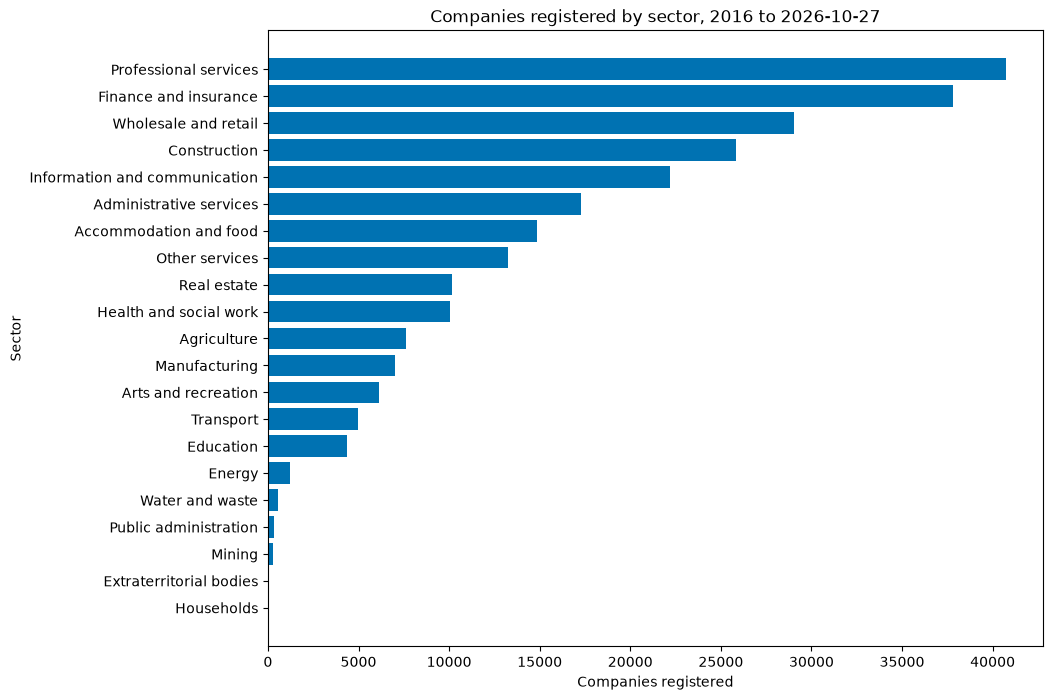

Sectors in chart: 21


In [11]:
# Sectors only (no missing values), smallest first so the largest bar is at the top
sector_chart = recent["section_name"].value_counts().sort_values()

# Horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(sector_chart.index, sector_chart.values, color="#0072B2")

ax.set_title(f"Companies registered by sector, {sector_start_year} to {last_date}")
ax.set_xlabel("Companies registered")
ax.set_ylabel("Sector")

fig.savefig("../figures/03_registrations_by_sector.png", dpi=150, bbox_inches="tight")
plt.show()

# Check: number of sectors in the chart
print("Sectors in chart:", len(sector_chart))

Professional services, Finance and insurance and Wholesale and retail are the three largest sectors. Several sectors at the bottom of the chart have very few companies, so section 4 ranks only sectors with at least 100 companies, the same rule as SQL Query 3.1.

### 2.4 Summary

- Registrations fell to their lowest level in 2009 (13,465) and rose almost every year from 2010. The highest year is 2025, with 26,533 companies.
- In 2020 registrations dipped slightly, then reached 25,669 in 2021 and fell back to 21,637 in 2022. Registrations were already rising before 2016, so the chart does not show a clear Brexit effect.
- Dublin has 227,457 companies, 44.4% of the total. No other county comes close.
- From 2016, the largest sectors are Professional services (40,739), Finance and insurance (37,803) and Wholesale and retail (29,048).